<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
            Contribuciones a la guia por: <br>
            - Deimer Miranda Montoya (2023)<br>
            - Luis Fernando Becerra Monsalve (2024)
        </td>    
        </td>    
    </tr>
</table>

### Optimización de funciones

Vamos a comparar el desempeño de los optimizadores gradiente descendente y algoritmo genético. Para ello usaremos una función no convexa con la cual trabajamos en la Practica 1.



https://github.com/Valdecy/pyMetaheuristic

In [1]:
import numpy as np
from numpy.random import rand
import matplotlib.pyplot as plt
from matplotlib import cm

No es necesario derivar la función 

In [2]:
#Minimizacion de una funcion 2D
#f(x,y)=(x^2+y-11)^2+(x+y^2-7)^2
def objective_func(solution):
  term1 = (solution[0]**2+solution[1]-11)**2
  term2 = (solution[0]+solution[1]**2-7)**2
  return term1+term2

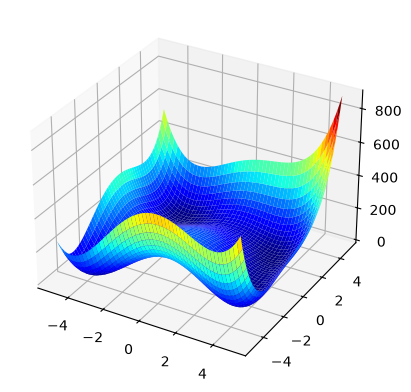

In [3]:
#Grafica de la funcion
x = np.linspace(-5, 5, 1000)
y = np.linspace(-5, 5, 1000)
xv, yv = np.meshgrid(x, y)
feval = objective_func([xv,yv])
ax = plt.figure().add_subplot(111,projection='3d')
ax.plot_surface(xv, yv, feval, cmap=cm.jet)

### Gradiente descendiente

Recordemos el método del gradiente descendiente:
1. Necesitamos conocer la primera derivada de la función objetivo: el gradiente. Para nuestro ejemplo, dado que tenemos una función en dos dimensiones, el gradiente será un vector con dos componentes.


In [4]:
#Funcion que evalua el gradiente en un punto solucion
def derivative(X):
  x = X[0]
  y = X[1]
  term0 = 4*x**3+4*x*y-42*x+2*y**2-14
  term1 = 2*x**2+4*x*y+4*y**3-26*y-22
  gradiente = np.array([term0,term1])
  return gradiente

2. El algoritmo iterativo: cada iteración proporciona una posible solución de la función de optimización. El punto inicial lo seleccionamos de forma aleatoria, y lo actualizamos en cada iteración restando el gradiente escalado con el paso de aprendizaje.

In [5]:
#Funcion del gradiente descendente
def gradient_descent(objective_func, derivative, bounds, n_iter, step_size):
  # Generamos el punto inicial de forma aleatoria
  solution0 = bounds[:,0]+rand(len(bounds))*(bounds[:,1]-bounds[:,0])
  solution1 = bounds[:,0]+rand(len(bounds))*(bounds[:,1]-bounds[:,0])
  solution = np.array([solution0,solution1])
	# Algoritmo iterativo
  for i in range(n_iter):
		#1. Calculo del gradiente
    gradiente = derivative(solution)
		#2. Actualizacion de la solucion
    solution = solution - step_size*gradiente
  	#3. Evaluacion de la solucion
    solution_eval = objective_func(solution)
    #print('>%d f(%s) = %.5f' % (i, solution, solution_eval))
  return solution

In [6]:
# Deliminatos el rango de los datos
bounds = np.asarray([[-4.0, 4.0]])
# Definimos el numero de iteraciones
n_iter = 500
# Seleccionamos la longitud del paso
step_size = 0.01
# Aplicamos el algoritmo de gradiente descendente
solution = gradient_descent(objective_func, derivative, bounds, n_iter, step_size)
#Guardamos la solucion para la comparacion
xopGD, yopGD = solution
fevalGD = objective_func(solution)

[7.88860905e-31]


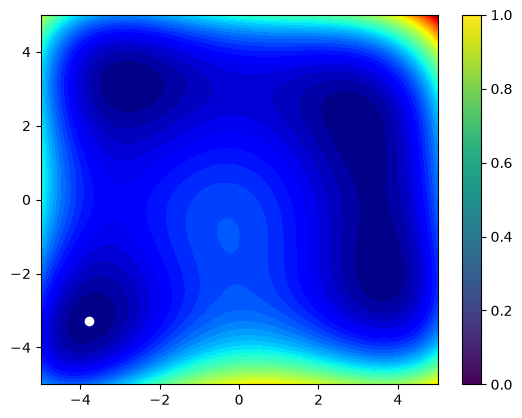

In [7]:
#Grafica de los contornos y punto optimo
plt.contourf(xv, yv, feval, levels=50, cmap='jet')
plt.scatter(xopGD, yopGD,c='white',marker='o')
plt.colorbar()
print(fevalGD)

# PSO y ACO: pyMetaheuristic

pyMetaheuristic es una biblioteca de Python orientada a la implementación y experimentación con algoritmos metaheurísticos para resolver problemas de optimización. Es especialmente útil en contextos académicos porque permite comparar diferentes técnicas de búsqueda sin tener que implementar cada algoritmo desde cero.


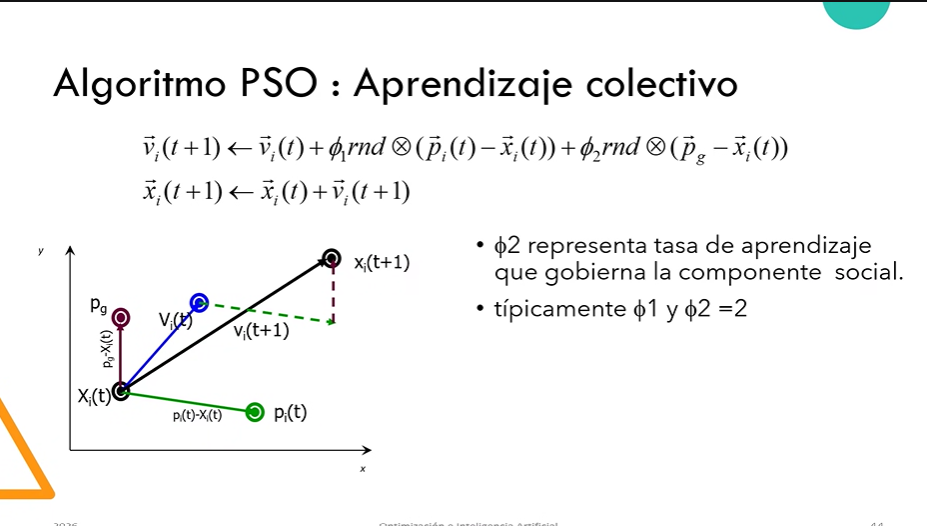





In [8]:
#Instalacion de la libreria
#!pip install pymetaheuristic

In [9]:
#Importar libreria pygad
import pymetaheuristic

La libreria pymetaheuristic.optimize() identifica el algoritmo PSO como algorithm="pso". Este algoritmo realiza la actualización de la particula mediante la ecuación:

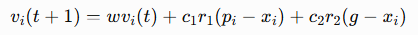

donde:

*  w corresponde a la inercia y controla cuánto continúa una partícula moviéndose en la dirección actual. Valores altos de w favorecen la exploración del espacio de búsqueda, mientras que valores bajos favorecen la explotación de las soluciones encontradas.

*  c1 corresponde al coeficiente cognitivo y controla qué tanto una partícula se mueve hacia su mejor posición encontrada. Valores altos de c1 implican un mayor peso de la experiencia individual de la partícula.

*  c2 corresponde al coeficiente social y controla qué tanto una partícula se mueve hacia la mejor posición encontrada por toda la población. Valores altos de c2 implican un mayor peso de la experiencia colectiva.

*  swarm_size indica el número de partículas que conforman la población.

In [10]:
# Optimize - Run
result = pymetaheuristic.optimize(
                                  algorithm                  = 'pso', # 'pso' or 'aco'
                                  target_function            = objective_func,
                                  min_values                 = (-4,-4),
                                  max_values                 = (4,4),
                                  max_steps                  = 200, # iterations
                                  store_history              = True,
                                  store_population_snapshots = True,
                                  swarm_size                 = 30, #Numero de particulas
                                  w                          = 0.9, #Inercia 90% de inercia
                                  c1                         = 2, #Coeficiente cognitivo: 2 valor recomendado
                                  c2                         = 2 #Coeficiente social: 2 valor recomendado, igual al cognitivo 
                                )

In [11]:
#Extraemos la mejor solucion
solution = result.best_position # mejor posicion de la particula
solution_fitness =  result.best_fitness # val minimo de la funcion objetivo
print(f"Parameters of the best solution : {solution}")
print(f"Fitness value of the best solution = {solution_fitness}")

prediction = objective_func(solution)
print(f"Valor optimo para la funcion: = {prediction}")

#Guardamos la solucion para la comparacion
xopPSO, yopPSO = solution
fevalPSO = prediction

Parameters of the best solution : [3.588204330026717, -1.8409961328569446]
Fitness value of the best solution = 0.00167816192360316
Valor optimo para la funcion: = 0.00167816192360316


In [18]:
#Grafica de convergencia
fig = pymetaheuristic.plot_convergence(result, show = True, x_axis = "steps", renderer = 'colab')

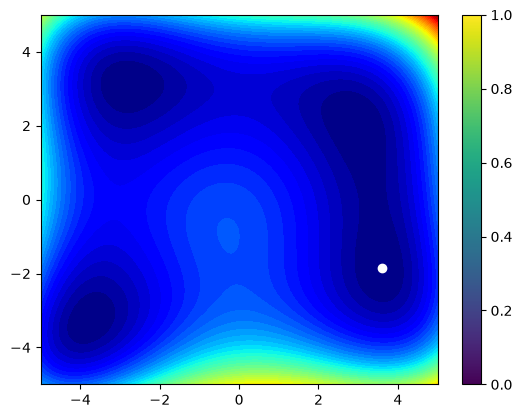

In [13]:
#Grafica de los contornos y punto optimo
plt.contourf(xv, yv, feval, levels=50, cmap='jet')
plt.scatter(xopPSO, yopPSO,c='white',marker='o')
plt.colorbar()

# COLONIA DE HORMIGAS

Para la optimización de funciones continuas, pymetaheuristic emplea la función ACOR.

In [14]:
# Optimize - Run
result = pymetaheuristic.optimize(
                                  algorithm                  = "acor", # funciones continuas 
                                  target_function            = objective_func,
                                  min_values                 = (-4, -4),
                                  max_values                 = ( 4,  4),
                                  max_steps                  = 25, # iterations
                                  store_history              = True,
                                  store_population_snapshots = True,
                                  population_size            = 30 #Tamaño de la población
                                )

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pymetaheuristic\src\engines\_ported_common.py:153: UserWarning: [acor] Source task-level repair/history is mapped to ProblemSpec evaluation; source task history is not tracked.
  self._warn_once(


In [15]:
#Extraemos la mejor solucion
solution = result.best_position
solution_fitness =  result.best_fitness
print(f"Parameters of the best solution : {solution}")
print(f"Fitness value of the best solution = {solution_fitness}")

prediction = objective_func(solution)
print(f"Valor optimo para la funcion: = {prediction}")

#Guardamos la solucion para la comparacion
xopACO, yopACO = solution
fevalACO = prediction

Parameters of the best solution : [3.6077789192306073, -1.8386820042709355]
Fitness value of the best solution = 0.03159760146948211
Valor optimo para la funcion: = 0.03159760146948211


In [16]:
#Grafica de convergencia
fig = pymetaheuristic.plot_convergence(result, show = True, x_axis = "steps", renderer = 'colab')

0.03159760146948211


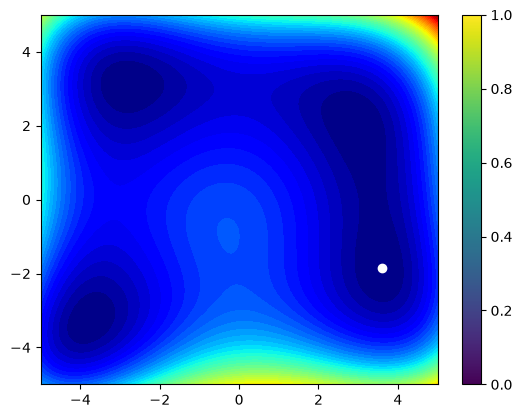

In [17]:
#Grafica de los contornos y punto optimo
plt.contourf(xv, yv, feval, levels=50, cmap='jet')
plt.scatter(xopACO, yopACO,c='white',marker='o')
plt.colorbar()
print(fevalACO)